# Prototype with interactions

**Data source:** none (layout only). Base images: the approved low-fidelity prototype of Part 4 (`lowfi_main_screen.png`, `lowfi_detail_screen.png`).
**Date:** 2026-11-05, updated 2026-11-09 for the refined dashboard
**Authors:** Group 3, Presentation and Visualization (Infovis2627)
**Description:** Part 5, task 5.3. The approved wireframes (redrawn for a 16:9 screen when the dashboard was refined) are completed with the planned interactions: each one is marked with its number (I1 to I12, see `interaction_plan.ipynb`) at the place where it happens, and what the interaction shows (month rule and outline, tooltips, selected country, animation) is drawn in.

---

## Contents

1. [Data loading](#1.-Data-loading)
2. [Initial exploration](#2.-Initial-exploration)
3. [Cleaning and preparation](#3.-Cleaning-and-preparation)
4. [Analysis: where each interaction goes](#4.-Analysis:-where-each-interaction-goes)
5. [Accessible visualisation: annotated wireframes](#5.-Accessible-visualisation:-annotated-wireframes)
6. [Export](#6.-Export)
7. [Conclusions](#Conclusions)

In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import sys
from pathlib import Path

import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image

PART4_IMAGES = Path('../../Part 4 - Chart Selection and Encoding/images')
IMAGES_DIR = Path('../images')
OUTPUT_DIR = Path('prototype_interactions_output')
IMAGES_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

INK, MARK = '#1A1A1A', '#0066CC'     # marks in the focus blue, numbers in white (contrast 5.6:1)
plt.rcParams.update({'font.family': 'DejaVu Sans'})
print('Python', sys.version.split()[0], '| matplotlib', matplotlib.__version__)

Python 3.13.18 | matplotlib 3.11.2


## 1. Data loading

In [2]:
# ── Load the approved wireframes (images, in pixels) ─────────────────────────
# The top 60 px hold the Part 4 figure title, which is replaced by a new title here
TITLE_STRIP = 60
main_wireframe = Image.open(PART4_IMAGES / 'lowfi_main_screen.png').convert('RGB')
detail_wireframe = Image.open(PART4_IMAGES / 'lowfi_detail_screen.png').convert('RGB')
main_wireframe = main_wireframe.crop((0, TITLE_STRIP, main_wireframe.width, main_wireframe.height))
detail_wireframe = detail_wireframe.crop((0, TITLE_STRIP, detail_wireframe.width, detail_wireframe.height))
print('Main:', main_wireframe.size, '| Detail:', detail_wireframe.size)

Main: (1440, 820) | Detail: (1440, 820)


## 2. Initial exploration

The interactions come from `interaction_plan.csv` (task 5.1).

## 3. Cleaning and preparation

Not applicable.

## 4. Analysis: where each interaction goes

In [3]:
# ── Position of each mark, in px of the 1536 x 864 layout of Part 4 ──────────
plan = pd.read_csv('interaction_plan_output/interaction_plan.csv')
names = dict(zip(plan['id'], plan['name']))

# The wireframes of lowfi_prototype.ipynb are 7.2 inches wide at 200 dpi, with the layout drawn in an axes
# that starts 0.5 % from the left and ends 0.5 % above the bottom; this turns layout px into image px
LAYOUT_W, LAYOUT_H, DPI, FIG_W = 1536, 864, 200, 7.2
FIG_H = FIG_W * LAYOUT_H / LAYOUT_W + 0.35
SCALE = 0.99 * FIG_W * DPI / LAYOUT_W
AXES_TOP = (FIG_H - 0.005 * FIG_H - 0.99 * FIG_W * LAYOUT_H / LAYOUT_W) * DPI   # px from the top of the image

def to_image(x, y):
    return 0.005 * FIG_W * DPI + SCALE * x, AXES_TOP + SCALE * y - TITLE_STRIP

FRAME_MARKS = {'I1': [(1500, 150)], 'I2': [(1500, 215)], 'I3': [(300, 64)], 'I4': [(1400, 322)], 'I12': [(712, 64)]}
MAIN_MARKS = {**FRAME_MARKS, 'I5': [(700, 222), (1500, 400)], 'I6': [(965, 326)], 'I11': [(1192, 172)]}
DETAIL_MARKS = {**FRAME_MARKS, 'I6': [(1192, 311)], 'I7': [(1500, 465), (600, 248)], 'I8': [(467, 172)],
                'I9': [(1500, 382)], 'I10': [(677, 450)], 'I11': [(577, 172)]}
placed = set(MAIN_MARKS) | set(DETAIL_MARKS)
print(f'{sum(map(len, MAIN_MARKS.values()))} marks on the main screen, {sum(map(len, DETAIL_MARKS.values()))} on the detail screen; '
      f'all {len(names)} interactions placed: {placed == set(names)} | scale {SCALE:.3f} image px per layout px')

9 marks on the main screen, 12 on the detail screen; all 12 interactions placed: True | scale 0.928 image px per layout px


## 5. Accessible visualisation: annotated wireframes

Each interaction is a numbered circle (white number on the focus blue, contrast 5.6:1), at every place where it happens, and a legend under the wireframe repeats the numbers with their names, so the figure does not depend on colour. Dashed outlines show what an interaction changes.

In [4]:
# ── Drawing helpers (all positions in layout px, turned into image px) ───────

def number_mark(ax, xy, label):
    ax.add_patch(plt.Circle(to_image(*xy), 17, facecolor=MARK, edgecolor='white', linewidth=1.5, zorder=5))
    ax.text(*to_image(*xy), label, ha='center', va='center', fontsize=5.5 if len(label) > 2 else 6, color='white',
            weight='bold', zorder=6)


def rectangle(ax, x, y, w, h, **style):
    left, top = to_image(x, y)
    ax.add_patch(plt.Rectangle((left, top), w * SCALE, h * SCALE, **style))


def line(ax, xs, ys, **style):
    points = [to_image(x, y) for x, y in zip(xs, ys)]
    ax.plot([p[0] for p in points], [p[1] for p in points], **style)


def tooltip(ax, x, y, text, w=230):
    rectangle(ax, x, y, w, 52, facecolor='white', edgecolor=INK, linewidth=0.8, zorder=4)
    ax.text(*to_image(x + 8, y + 26), text, fontsize=5, va='center', color=INK, zorder=4)


def annotated(image, marks, extra, legend_ids, title, file_name):
    width, height = image.size
    total = height + 150 + 50                       # 50 px for the title above, 150 px for the legend below
    fig = plt.figure(figsize=(7.2, 7.2 * total / width))
    ax = fig.add_axes([0, 150 / total, 1, height / total])
    ax.imshow(image)
    ax.set_xlim(0, width)
    ax.set_ylim(height, 0)
    ax.axis('off')
    extra(ax)
    for label, positions in marks.items():
        for xy in positions:
            number_mark(ax, xy, label)
    legend = '   '.join(f'{i} {names[i]}' for i in legend_ids)
    fig.text(0.01, 75 / total, 'Interactions: ' + legend, fontsize=6.5, color=INK, wrap=True, va='center')
    fig.text(0.01, 1 - 12 / total, title, fontsize=10, color=INK, va='top')
    fig.savefig(IMAGES_DIR / file_name, dpi=200)
    return fig


def main_extra(ax):
    # I5: the same month marked by a rule in C1 and C3 and by an outline around its cells in the C2 heatmap
    line(ax, [700, 700], [238, 490], color=MARK, linestyle='--', linewidth=1.2)
    line(ax, [941, 941], [600, 790], color=MARK, linestyle='--', linewidth=1.2)
    cell_w, cell_h = (600 - 200) / 12, (282 - 80) / 6
    rectangle(ax, 16 + 97 + 7 * cell_w - 1, 533 + 55 - 1, cell_w, 6 * cell_h, facecolor='none', edgecolor=MARK, linewidth=1.8)
    # I6: tooltip next to the rule
    tooltip(ax, 715, 300, 'August 2016 - City Hotel\nGuests: value (example)')


def detail_extra(ax):
    # I7: the selected country: a band on its row of the dumbbell and of the box plots, a green bubble with its trail
    rectangle(ax, 26, 239, 585, 18, facecolor='none', edgecolor=MARK, linewidth=1.5, linestyle='--')
    rectangle(ax, 26, 577, 1200, 18, facecolor='none', edgecolor=MARK, linewidth=1.5, linestyle='--')
    trail_x, trail_y = [760, 800, 850, 905, 950], [420, 380, 350, 330, 300]
    line(ax, trail_x, trail_y, color=MARK, linewidth=1, linestyle=':')
    centre = to_image(trail_x[-1], trail_y[-1])
    ax.add_patch(plt.Circle(centre, 15, facecolor='white', edgecolor=MARK, linewidth=2, zorder=3))
    # I6: tooltip on the selected bubble
    tooltip(ax, 975, 285, 'Brazil - March\nGuests: value (example)', w=200)


print('Helpers ready')

Helpers ready


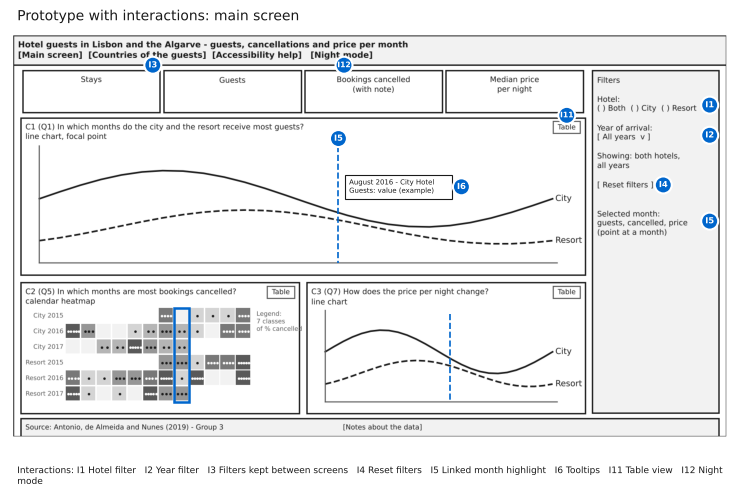

In [5]:
# ── Main screen with interactions ─────────────────────────────────────────────
annotated(main_wireframe, MAIN_MARKS, main_extra, ['I1', 'I2', 'I3', 'I4', 'I5', 'I6', 'I11', 'I12'],
          'Prototype with interactions: main screen', 'prototype_main_interactions.png')
plt.show()

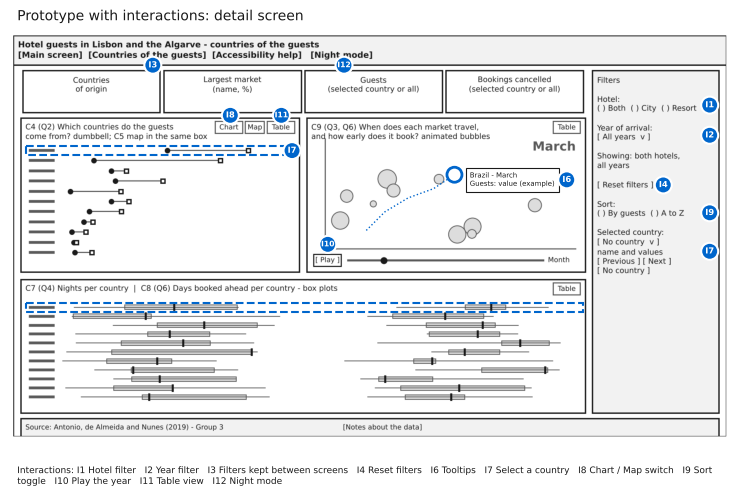

In [6]:
# ── Detail screen with interactions ───────────────────────────────────────────
annotated(detail_wireframe, DETAIL_MARKS, detail_extra, ['I1', 'I2', 'I3', 'I4', 'I6', 'I7', 'I8', 'I9', 'I10', 'I11', 'I12'],
          'Prototype with interactions: detail screen', 'prototype_detail_interactions.png')
plt.show()

## 6. Export

In [7]:
# ── Export: positions of the marks ────────────────────────────────────────────
marks = pd.DataFrame([(screen, i, x, y) for screen, d in [('main', MAIN_MARKS), ('detail', DETAIL_MARKS)]
                      for i, positions in d.items() for x, y in positions],
                     columns=['screen', 'interaction', 'x_layout_px', 'y_layout_px'])
marks.to_csv(OUTPUT_DIR / 'interaction_marks.csv', index=False)
marks

,screen,interaction,x_layout_px,y_layout_px
0,main,I1,1500,150
1,main,I2,1500,215
2,main,I3,300,64
3,main,I4,1400,322
4,main,I12,712,64
5,main,I5,700,222
6,main,I5,1500,400
7,main,I6,965,326
8,main,I11,1192,172
9,detail,I1,1500,150


## Conclusions

The 16:9 layout of Part 4 already holds every control: filters, reset, links between screens, night mode, a Table button on each chart, the Chart / Map switch, Play and the month slider, the sort toggle and the selected-country panel with its list, Previous / Next and "No country". The interactions add only what they show: the month rule and outline, tooltips, and the selected country in every chart.